

## **Project Overview**

This project investigates the ability of the **Qwen2-VL-7B** vision-language model to recognize Persian book titles directly from book cover images.

The model is fine-tuned using the **LoRA (Low-Rank Adaptation)** technique with the **Unsloth** framework to achieve efficient and memory-friendly training. The training dataset is based on the **`shenasa/bookroom-persian-book-covers-and-titles`** dataset, which contains Persian book cover images paired with their corresponding titles.

After fine-tuning, the model is evaluated on its ability to accurately predict Persian book titles from unseen book cover images. Performance is assessed using multiple text generation metrics, including:

* Exact Match (EM)
* Levenshtein Accuracy
* Word-level F1 Score
* Character Error Rate (CER)
* Word Error Rate (WER)

The objective of this project is to evaluate how effectively a vision-language model can learn to read and generate Persian text from book cover images through parameter-efficient fine-tuning.


## **Install required packages**

In [ ]:
%%capture
import os, re

if "COLAB_" not in "".join(os.environ.keys()):
    !pip install unsloth  # Install Unsloth in local or cloud environments
else:
    import torch
    v = re.match(r'[\d]{1,}\.[\d]{1,}', str(torch.__version__)).group(0)
    xformers = 'xformers==' + {
        '2.10': '0.0.34',
        '2.9': '0.0.33.post1',
        '2.8': '0.0.32.post2'
    }.get(v, "0.0.34")

    !pip install sentencepiece protobuf "datasets==4.3.0" "huggingface_hub>=0.34.0" hf_transfer
    !pip install --no-deps unsloth_zoo bitsandbytes accelerate {xformers} peft trl triton unsloth
    !pip install --no-deps --upgrade "torchao>=0.16.0"

!pip install transformers==4.56.2
!pip install --no-deps trl==0.22.2
!pip install Levenshtein matplotlib


In [ ]:
# Improve CUDA memory allocation to reduce fragmentation

import os

os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

### Persian text rendering support

Enable proper rendering of Persian text in Matplotlib charts.

By default, Matplotlib does not correctly join Arabic/Persian characters or support right-to-left (RTL) text. The `arabic_reshaper` and `python-bidi` libraries are used to ensure Persian labels are displayed correctly.

In [ ]:
# Install packages for proper Persian text rendering
!pip install -q arabic_reshaper python-bidi

import arabic_reshaper
from bidi.algorithm import get_display

def fa(text):
    """Prepare Persian text for correct display in Matplotlib (character shaping and right-to-left rendering)."""
    reshaped = arabic_reshaper.reshape(str(text))
    return get_display(reshaped)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.2/296.2 kB 26.3 MB/s eta 0:00:00


## **Load the pretrained model**
Qwen2-VL-7B was selected for its strong multilingual vision-language capabilities, making it a suitable candidate for Persian book title recognition.

In [ ]:
import torch

print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")

True
NVIDIA L4


In [ ]:
!nvidia-smi

Sun Jul  5 22:24:08 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   41C    P8             17W /   72W |       3MiB /  23034MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import io
from contextlib import redirect_stdout, redirect_stderr
from unsloth import FastVisionModel
import torch

# Load the pretrained Qwen2-VL-7B model optimized for Persian OCR tasks

try:
    with redirect_stdout(io.StringIO()), redirect_stderr(io.StringIO()):
        model, tokenizer = FastVisionModel.from_pretrained(
            "unsloth/Qwen2-VL-7B-Instruct-bnb-4bit",
            load_in_4bit=True,
            use_gradient_checkpointing="unsloth",
        )

    print("-"*20)
    print("Qwen2-VL-7B model loaded successfully.")
    print("-"*20)

except Exception as e:
    print("-"*20)
    print(f"Failed to load the model:\n{e}")
    print("-"*20)

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


🦥 Unsloth Zoo will now patch everything to make training faster!


model.safetensors:   0%|          | 0.00/5.90G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/238 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/567 [00:00<?, ?B/s]

The image processor of type `Qwen2VLImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. Note that this behavior will be extended to all models in a future release.


... (4 outputs left out)

added_tokens.json:   0%|          | 0.00/392 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/614 [00:00<?, ?B/s]

chat_template.json: 0.00B [00:00, ?B/s]

--------------------
Qwen2-VL-7B model loaded successfully.
--------------------


## **Configure LoRA adapters**
Add LoRA adapters for parameter-efficient fine-tuning.
This approach trains only a small fraction of the model parameters while keeping the pretrained weights frozen.

In [ ]:
# LoRA configuration parameters

FINETUNE_VISION = True
FINETUNE_LANGUAGE = True

TRAIN_ATTENTION = True
TRAIN_MLP = True

LORA_R = 16
LORA_ALPHA = 32
LORA_DROPOUT = 0

RANDOM_SEED = 3407

In [ ]:
# Configure LoRA adapters for parameter-efficient fine-tuning

model = FastVisionModel.get_peft_model(
    model,
    finetune_vision_layers=FINETUNE_VISION,
    finetune_language_layers=FINETUNE_LANGUAGE,
    finetune_attention_modules=TRAIN_ATTENTION,
    finetune_mlp_modules=TRAIN_MLP,
    r=LORA_R,
    lora_alpha=LORA_ALPHA,
    lora_dropout=LORA_DROPOUT,
    bias="none",
    random_state=RANDOM_SEED,
)

## **Dataset Preparation**

This project uses the **`shenasa/bookroom-persian-book-covers-and-titles`** dataset, which contains Persian book cover images and their corresponding titles.



In [ ]:
# Dataset configuration

TRAIN_SAMPLES = 1000
TEST_SAMPLES = 200

In [ ]:
from datasets import load_dataset

dataset_name = "shenasa/bookroom-persian-book-covers-and-titles"

# Load the training dataset
train_dataset = load_dataset(
    dataset_name,
    split=f"train[:{TRAIN_SAMPLES}]"
)

# Load the test split if available; otherwise, create one from the training set
try:
    test_dataset = load_dataset(
        dataset_name,
        split=f"test[:{TEST_SAMPLES}]"
    )
except Exception:
    test_dataset = load_dataset(
        dataset_name,
        split=f"train[{TRAIN_SAMPLES}:{TRAIN_SAMPLES + TEST_SAMPLES}]"
    )

print("-"*50)
print(f"Training samples: {len(train_dataset):,}")
print(f"Test samples: {len(test_dataset):,}")
print("-"*50)

--------------------------------------------------
Training samples: 1,000
Test samples: 200
--------------------------------------------------


In [ ]:
# Inspect the dataset
train_dataset

Dataset({
    features: ['image', 'text'],
    num_rows: 1000
})

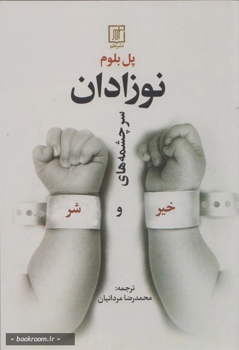

Title: نوزادان؛ سرچمه های خیر و شر


In [ ]:
from IPython.display import display

sample = train_dataset[200]

image = sample["image"].copy()
image.thumbnail((350, 350))

display(image)
print(f"Title: {sample['text']}")

## **Format Training Conversations**

Each training sample is structured as a conversation between the user and the assistant. The user provides a book cover image along with an instruction, and the assistant returns the corresponding Persian book title.

In [ ]:
# Prompt configuration

INSTRUCTION = (
    "You are an expert OCR assistant. "
    "Extract the exact Persian book title from the provided book cover image."
)

In [ ]:
# Convert each dataset sample into the Qwen2-VL conversation format

def convert_to_conversation(sample):
    """Convert a dataset sample into the Qwen2-VL conversation format."""

    conversation = [
        {
            "role": "user",
            "content": [
                {"type": "text", "text": INSTRUCTION},
                {"type": "image", "image": sample["image"]},
            ],
        },
        {
            "role": "assistant",
            "content": [
                {"type": "text", "text": sample["text"]},
            ],
        },
    ]

    return {"messages": conversation}

In [ ]:
# Apply the conversation formatting to the training and test datasets
converted_train_dataset = train_dataset.map(convert_to_conversation)
converted_test_dataset = test_dataset.map(convert_to_conversation)

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Map:   0%|          | 0/200 [00:00<?, ? examples/s]

### Display a formatted sample

In [ ]:
def show_sample(sample):
    """Display a formatted training sample without rendering the image."""

    for key, value in sample.items():
        if key == "images":
            print(f"images: [{len(value)} image(s), type={type(value[0])}]")

        elif key == "messages":
            for message in value:
                role = message["role"]

                # Display only the text content
                texts = [
                    content.get("text", "")
                    for content in message["content"]
                    if "text" in content
                ]

                print(f"[{role}]: {texts}")

        else:
            print(f"{key}: {value}")

show_sample(converted_train_dataset[200])

image: <PIL.WebPImagePlugin.WebPImageFile image mode=RGB size=409x600 at 0x7C2F9FA764B0>
text: نوزادان؛ سرچمه های خیر و شر
[user]: ['You are an expert OCR assistant. Extract the exact Persian book title from the provided book cover image.', None]
[assistant]: ['نوزادان؛ سرچمه های خیر و شر']


## **Evaluate the pretrained model**

Before fine-tuning, let's evaluate the pretrained Qwen2-VL model to establish a baseline for Persian book title recognition.

In [ ]:
sample_idx = 20

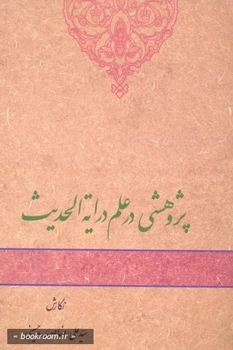

Ground truth: پژوهشی در علم درایه الحدیث


In [ ]:
from IPython.display import display

image = test_dataset[sample_idx]["image"].copy()

image.thumbnail((350, 350))
display(image)

print(f"Ground truth: {test_dataset[sample_idx]['text']}")

In [ ]:
# Enable inference mode for faster generation
FastVisionModel.for_inference(model)

# Select a sample from the test dataset
image = test_dataset[sample_idx]["image"]

# Create the inference prompt
instruction = "Extract the exact Persian book title from this cover image."

messages = [
    {
        "role": "user",
        "content": [
            {"type": "image"},
            {"type": "text", "text": INSTRUCTION},
        ],
    }
]

# Prepare the model inputs
input_text = tokenizer.apply_chat_template(
    messages,
    add_generation_prompt=True,
)

inputs = tokenizer(
    image,
    input_text,
    add_special_tokens=False,
    return_tensors="pt",
).to("cuda")

from transformers import TextStreamer

# Stream the generated text during inference
text_streamer = TextStreamer(
    tokenizer,
    skip_prompt=True,
)

print(f"Ground truth : {test_dataset[sample_idx]['text']}")
print("Prediction   : ", end="")

_ = model.generate(
    **inputs,
    streamer=text_streamer,
    max_new_tokens=128,
    use_cache=True,
    do_sample=False,
)

Ground truth : پژوهشی در علم درایه الحدیث
Prediction   : 

/usr/local/lib/python3.12/dist-packages/bitsandbytes/_ops.py:239: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)
/usr/local/lib/python3.12/dist-packages/bitsandbytes/_ops.py:186: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)
/usr/local/lib/python3.12/dist-packages/bitsandbytes/_ops.py:239: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)
/usr/local/lib/python3.12/dist-packages/bitsandbytes/_ops.py:186: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)
/usr/local/lib/python3.12/dist-packages/bits

The exact Persian book title from the provided book cover image is "پرده‌های علم در آیت‌الله".<|im_end|>


## **Baseline Evaluation**

Evaluate the pretrained model on the test set before fine-tuning and report the following metrics:

- Exact Match
- Levenshtein Accuracy
- Word-level F1
- Character Error Rate (CER)
- Word Error Rate (WER)

In [ ]:
MAX_NEW_TOKENS = 64

In [ ]:
import Levenshtein
from tqdm import tqdm


def get_prediction(model, tokenizer, image):
    """Generate a prediction for a single book cover image."""

    messages = [
        {
            "role": "user",
            "content": [
                {"type": "image"},
                {"type": "text", "text": INSTRUCTION},
            ],
        }
    ]

    input_text = tokenizer.apply_chat_template(
        messages,
        add_generation_prompt=True,
    )

    inputs = tokenizer(
        image,
        input_text,
        add_special_tokens=False,
        return_tensors="pt",
    ).to("cuda")

    output = model.generate(
        **inputs,
        max_new_tokens=MAX_NEW_TOKENS,
        use_cache=True,
        do_sample=False,
    )

    decoded = tokenizer.decode(output[0], skip_special_tokens=True)

    # Return only the assistant's response
    if "assistant" in decoded.lower():
        decoded = decoded.split("assistant")[-1].strip()

    return decoded.strip()


def exact_match(prediction, ground_truth):
    """Compute the Exact Match score."""
    return int(prediction.strip() == ground_truth.strip())


def levenshtein_accuracy(prediction, ground_truth):
    """Compute the normalized Levenshtein similarity (0–1)."""

    prediction = prediction.strip()
    ground_truth = ground_truth.strip()

    if len(ground_truth) == 0:
        return 1.0 if len(prediction) == 0 else 0.0

    distance = Levenshtein.distance(prediction, ground_truth)

    return max(
        0.0,
        1.0 - distance / max(len(prediction), len(ground_truth)),
    )


def cer(prediction, ground_truth):
    """Compute the Character Error Rate (CER). Lower is better."""

    prediction = prediction.strip()
    ground_truth = ground_truth.strip()

    if len(ground_truth) == 0:
        return 0.0 if len(prediction) == 0 else 1.0

    distance = Levenshtein.distance(prediction, ground_truth)

    return distance / len(ground_truth)


def token_edit_distance(reference_tokens, predicted_tokens):
    """Compute the token-level edit distance."""

    n = len(reference_tokens)
    m = len(predicted_tokens)

    dp = [[0] * (m + 1) for _ in range(n + 1)]

    for i in range(n + 1):
        dp[i][0] = i

    for j in range(m + 1):
        dp[0][j] = j

    for i in range(1, n + 1):
        for j in range(1, m + 1):
            cost = (
                0
                if reference_tokens[i - 1] == predicted_tokens[j - 1]
                else 1
            )

            dp[i][j] = min(
                dp[i - 1][j] + 1,
                dp[i][j - 1] + 1,
                dp[i - 1][j - 1] + cost,
            )

    return dp[n][m]


def wer(prediction, ground_truth):
    """Compute the Word Error Rate (WER). Lower is better."""

    prediction_tokens = prediction.strip().split()
    ground_truth_tokens = ground_truth.strip().split()

    if len(ground_truth_tokens) == 0:
        return 0.0 if len(prediction_tokens) == 0 else 1.0

    distance = token_edit_distance(
        ground_truth_tokens,
        prediction_tokens,
    )

    return distance / len(ground_truth_tokens)


def word_f1(prediction, ground_truth):
    """Compute the word-level F1 score."""

    prediction_tokens = prediction.strip().split()
    ground_truth_tokens = ground_truth.strip().split()

    if not ground_truth_tokens:
        return 1.0 if not prediction_tokens else 0.0

    common = set(prediction_tokens) & set(ground_truth_tokens)

    if not common:
        return 0.0

    precision = (
        len(common) / len(prediction_tokens)
        if prediction_tokens
        else 0.0
    )

    recall = len(common) / len(ground_truth_tokens)

    if precision + recall == 0:
        return 0.0

    return 2 * precision * recall / (precision + recall)


def categorize_error(prediction, ground_truth):
    """Categorize prediction errors for qualitative analysis."""

    prediction = prediction.strip()
    ground_truth = ground_truth.strip()

    if prediction == ground_truth:
        return "Exact match"

    character_error = cer(prediction, ground_truth)

    prediction_words = prediction.split()
    ground_truth_words = ground_truth.split()

    if abs(len(prediction_words) - len(ground_truth_words)) >= 1 and character_error < 0.4:
        return "Word insertion/deletion"

    if character_error < 0.15:
        return "Minor character error"

    if character_error < 0.5:
        return "Moderate recognition error"

    return "Completely incorrect prediction"

In [ ]:
# Enable inference mode
FastVisionModel.for_inference(model)

baseline_results = []

print(f"Evaluating the pretrained model on {len(test_dataset)} test samples...")

for sample in tqdm(test_dataset):

    image = sample["image"]
    ground_truth = sample["text"].strip()

    prediction = get_prediction(
        model=model,
        tokenizer=tokenizer,
        image=image,
    )

    baseline_results.append(
        {
            "ground_truth": ground_truth,
            "prediction": prediction,
            "exact_match": exact_match(prediction, ground_truth),
            "levenshtein": levenshtein_accuracy(prediction, ground_truth),
            "word_f1": word_f1(prediction, ground_truth),
            "cer": cer(prediction, ground_truth),
            "wer": wer(prediction, ground_truth),
            "error": categorize_error(prediction, ground_truth),
        }
    )

# Compute the average evaluation metrics
num_samples = len(baseline_results)

baseline_exact_match = (
    sum(result["exact_match"] for result in baseline_results)
    / num_samples
    * 100
)

baseline_levenshtein = (
    sum(result["levenshtein"] for result in baseline_results)
    / num_samples
    * 100
)

baseline_word_f1 = (
    sum(result["word_f1"] for result in baseline_results)
    / num_samples
    * 100
)

baseline_cer = (
    sum(result["cer"] for result in baseline_results)
    / num_samples
    * 100
)

baseline_wer = (
    sum(result["wer"] for result in baseline_results)
    / num_samples
    * 100
)

Evaluating the pretrained model on 200 test samples...


100%|██████████| 200/200 [12:46<00:00,  3.83s/it]


In [ ]:
print("\nBaseline Evaluation Results")
print("-" * 40)
print(f"Exact Match          : {baseline_exact_match:.2f}%")
print(f"Levenshtein Accuracy : {baseline_levenshtein:.2f}%")
print(f"Word-level F1        : {baseline_word_f1:.2f}%")
print(f"Character Error Rate : {baseline_cer:.2f}%")
print(f"Word Error Rate      : {baseline_wer:.2f}%")


Baseline Evaluation Results
----------------------------------------
Exact Match          : 0.00%
Levenshtein Accuracy : 16.93%
Word-level F1        : 8.95%
Character Error Rate : 331.28%
Word Error Rate      : 313.97%


## **Fine-Tune the Model**

Fine-tune the Qwen2-VL-7B model using LoRA adapters and the Unsloth framework on the Persian book cover dataset.

### Check GPU memory

In [ ]:
# Display the current GPU memory usage

gpu_stats = torch.cuda.get_device_properties(0)

start_gpu_memory = round(torch.cuda.max_memory_reserved() / 1024**3, 3,)

max_gpu_memory = round(gpu_stats.total_memory / 1024**3,3,)

print(f"GPU: {gpu_stats.name}")
print(f"Total GPU memory : {max_gpu_memory:.2f} GB")
print(f"Reserved memory  : {start_gpu_memory:.2f} GB")

GPU: NVIDIA L4
Total GPU memory : 22.03 GB
Reserved memory  : 7.33 GB


### Configure the training pipeline

In [ ]:
# Training configuration
BATCH_SIZE = 2
GRADIENT_ACCUMULATION_STEPS = 4

NUM_EPOCHS = 3
LEARNING_RATE = 2e-4
WARMUP_RATIO = 0.05

WEIGHT_DECAY = 0.001
LOGGING_STEPS = 5

MAX_SEQ_LENGTH = 2048
OUTPUT_DIR = "outputs"

In [ ]:
from unsloth.trainer import UnslothVisionDataCollator
from trl import SFTTrainer, SFTConfig

# Switch the model to training mode
FastVisionModel.for_training(model)

trainer = SFTTrainer(
    model=model,
    tokenizer=tokenizer,
    data_collator=UnslothVisionDataCollator(model, tokenizer),
    train_dataset=converted_train_dataset,

    args=SFTConfig(
        per_device_train_batch_size=BATCH_SIZE,
        gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,

        num_train_epochs=NUM_EPOCHS,
        learning_rate=LEARNING_RATE,
        warmup_ratio=WARMUP_RATIO,

        optim="adamw_8bit",
        lr_scheduler_type="cosine",
        weight_decay=WEIGHT_DECAY,

        logging_steps=LOGGING_STEPS,
        seed=RANDOM_SEED,

        output_dir=OUTPUT_DIR,
        report_to="none",
        save_strategy="no",

        remove_unused_columns=False,
        dataset_text_field="",
        dataset_kwargs={"skip_prepare_dataset": True},

        max_length=MAX_SEQ_LENGTH,
    ),
)

trainer_stats = trainer.train()

print("-"*40)
print("Training completed successfully.")
print("-"*40)

Unsloth: Model does not have a default image size - using 512


==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 1,000 | Num Epochs = 3 | Total steps = 375
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 50,855,936 of 8,342,231,552 (0.61% trained)


Unsloth: Will smartly offload gradients to save VRAM!


/usr/local/lib/python3.12/dist-packages/bitsandbytes/_ops.py:239: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)
/usr/local/lib/python3.12/dist-packages/bitsandbytes/_ops.py:186: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)
/usr/local/lib/python3.12/dist-packages/bitsandbytes/_ops.py:239: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)
/usr/local/lib/python3.12/dist-packages/bitsandbytes/_ops.py:186: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)
/usr/local/lib/python3.12/dist-packages/bits

Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Step,Training Loss
5,2.997100
10,2.202000
15,0.854200
20,0.352600
25,0.239100
30,0.252000
35,0.217900
40,0.239000
45,0.321500
50,0.239000


----------------------------------------
Training completed successfully.
----------------------------------------


### Training Loss Curve

The training loss curve shows how the model's loss changes during fine-tuning, providing an indication of the learning progress.

In [ ]:
import matplotlib.pyplot as plt

plt.rcParams["font.size"] = 11
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["figure.figsize"] = (9, 4.5)

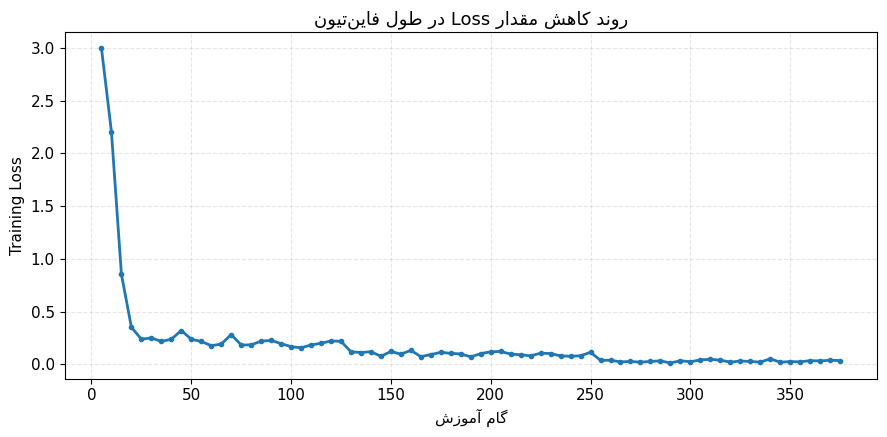


 آمار آموزش
-----------------------------------
Loss اولیه : 2.9971
Loss نهایی : 0.0367
درصد کاهش : 98.8%


In [ ]:
# Extract the training loss history
log_history = trainer.state.log_history

steps = [entry["step"] for entry in log_history if "loss" in entry]
losses = [entry["loss"] for entry in log_history if "loss" in entry]

# Plot the training loss curve
plt.figure(figsize=(9, 4.5))

plt.plot(
    steps,
    losses,
    linewidth=2,
    marker="o",
    markersize=3,
)

plt.xlabel(fa("گام آموزش"), fontsize=11)
plt.ylabel("Training Loss", fontsize=11)
plt.title(fa("روند کاهش مقدار Loss در طول فاین‌تیون"), fontsize=13)

plt.grid(alpha=0.3, linestyle="--")
plt.tight_layout()

plt.savefig(
    "training_loss_curve.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()

# Display training statistics
loss_reduction = (1 - losses[-1] / losses[0]) * 100

print("\n آمار آموزش")
print("-" * 35)
print(f"Loss اولیه : {losses[0]:.4f}")
print(f"Loss نهایی : {losses[-1]:.4f}")
print(f"درصد کاهش : {loss_reduction:.1f}%")


In [ ]:
# Calculate GPU memory usage after training

used_gpu_memory = round(torch.cuda.max_memory_reserved() / 1024**3, 2)
training_gpu_memory = round(used_gpu_memory - start_gpu_memory, 2)

gpu_usage = round((used_gpu_memory / max_gpu_memory) * 100, 2)
training_gpu_usage = round((training_gpu_memory / max_gpu_memory) * 100, 2)

training_time_seconds = trainer_stats.metrics["train_runtime"]
training_time_minutes = training_time_seconds / 60

print("\n Training Summary")
print("─" * 42)

print(f"{'Training Time':<25} {training_time_minutes:.2f} min")
print(f"{'Peak GPU Memory':<25} {used_gpu_memory:.2f} GB")
print(f"{'Training Memory':<25} {training_gpu_memory:.2f} GB")
print(f"{'GPU Memory Usage':<25} {gpu_usage:.2f}%")
print(f"{'Training Memory Usage':<25} {training_gpu_usage:.2f}%")


 Training Summary
──────────────────────────────────────────
Training Time             46.61 min
Peak GPU Memory           7.33 GB
Training Memory           0.00 GB
GPU Memory Usage          33.27%
Training Memory Usage     0.00%


## **Model Evaluation Before and After Fine-Tuning**

Evaluate both the baseline and fine-tuned models on the test set and compare their performance across multiple OCR evaluation metrics to measure the impact of fine-tuning.

In [ ]:
# Enable inference mode
FastVisionModel.for_inference(model)

finetuned_results = []

print(f"Evaluating the fine-tuned model on {len(test_dataset)} test samples...")

for sample in tqdm(test_dataset):

    image = sample["image"]
    ground_truth = sample["text"].strip()

    prediction = get_prediction(
        model=model,
        tokenizer=tokenizer,
        image=image,
    )

    finetuned_results.append(
        {
            "ground_truth": ground_truth,
            "prediction": prediction,
            "exact_match": exact_match(prediction, ground_truth),
            "levenshtein": levenshtein_accuracy(prediction, ground_truth),
            "word_f1": word_f1(prediction, ground_truth),
            "cer": cer(prediction, ground_truth),
            "wer": wer(prediction, ground_truth),
            "error": categorize_error(prediction, ground_truth),
        }
    )

# Compute the average evaluation metrics
num_samples = len(finetuned_results)

finetuned_exact_match = (
    sum(result["exact_match"] for result in finetuned_results)
    / num_samples
    * 100
)

finetuned_levenshtein = (
    sum(result["levenshtein"] for result in finetuned_results)
    / num_samples
    * 100
)

finetuned_word_f1 = (
    sum(result["word_f1"] for result in finetuned_results)
    / num_samples
    * 100
)

finetuned_cer = (
    sum(result["cer"] for result in finetuned_results)
    / num_samples
    * 100
)

finetuned_wer = (
    sum(result["wer"] for result in finetuned_results)
    / num_samples
    * 100
)

Evaluating the fine-tuned model on 200 test samples...


  0%|          | 0/200 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/bitsandbytes/backends/cuda/ops.py:468: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)
100%|██████████| 200/200 [08:48<00:00,  2.64s/it]


### Performance Comparison

In [ ]:
# Compare baseline and fine-tuned performance

comparison = [
    ("Exact Match", baseline_exact_match, finetuned_exact_match, True),
    ("Levenshtein Accuracy", baseline_levenshtein, finetuned_levenshtein, True),
    ("Word-level F1", baseline_word_f1, finetuned_word_f1, True),
    ("Character Error Rate (CER)", baseline_cer, finetuned_cer, False),    # Lower is better
    ("Word Error Rate (WER)", baseline_wer, finetuned_wer, False),         # Lower is better
]

print("\nPerformance Comparison")
print("=" * 90)

print(
    f"{'Metric':<30}"
    f"{'Baseline':>15}"
    f"{'Fine-Tuned':>15}"
    f"{'Improvement':>18}"
)

print("-" * 90)

for metric, baseline, finetuned, higher_is_better in comparison:

    improvement = (
        finetuned - baseline
        if higher_is_better
        else baseline - finetuned
    )

    print(
        f"{metric:<30}"
        f"{baseline:>14.2f}%"
        f"{finetuned:>15.2f}%"
        f"{improvement:>17.2f}%"
    )

print("-" * 90)


Performance Comparison
Metric                               Baseline     Fine-Tuned       Improvement
------------------------------------------------------------------------------------------
Exact Match                             0.00%          14.00%            14.00%
Levenshtein Accuracy                   16.93%          61.26%            44.32%
Word-level F1                           8.95%          44.22%            35.27%
Character Error Rate (CER)            331.28%          60.60%           270.68%
Word Error Rate (WER)                 313.97%          86.54%           227.43%
------------------------------------------------------------------------------------------


### Performance Visualization

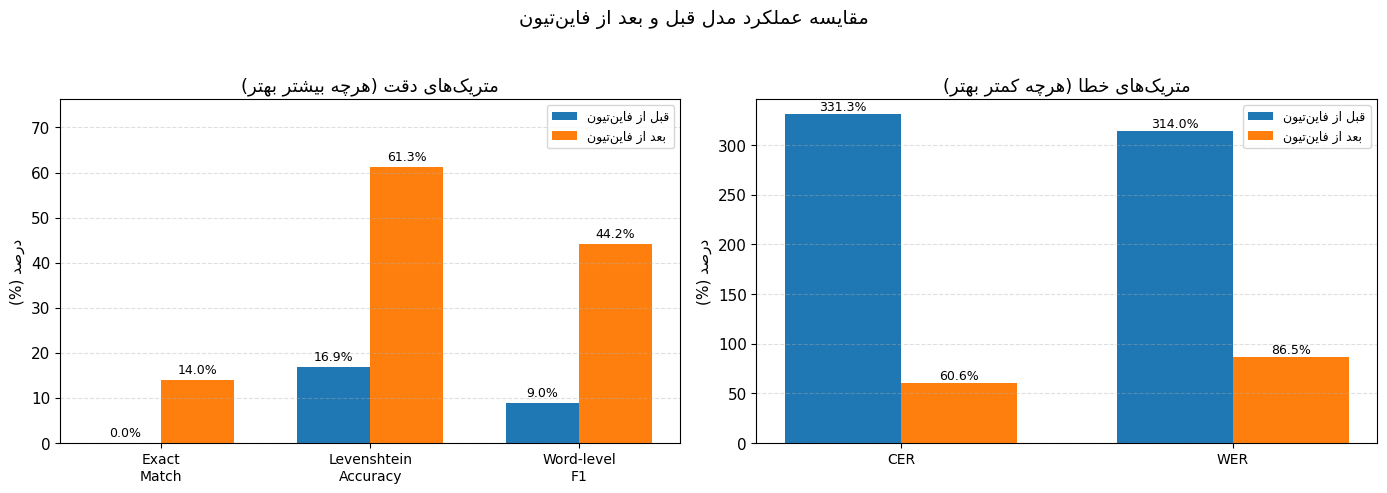

Figure saved as: performance_comparison.png


In [ ]:
import matplotlib.pyplot as plt
import matplotlib

# Configure the font for Persian text
matplotlib.rcParams["font.family"] = "DejaVu Sans"

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))


# Accuracy Metrics (Higher is Better)
accuracy_metrics = [
    "Exact\nMatch",
    "Levenshtein\nAccuracy",
    "Word-level\nF1",
]

baseline_accuracy = [
    baseline_exact_match,
    baseline_levenshtein,
    baseline_word_f1,
]

finetuned_accuracy = [
    finetuned_exact_match,
    finetuned_levenshtein,
    finetuned_word_f1,
]

width = 0.35
x1 = range(len(accuracy_metrics))

bars_before = ax1.bar(
    [i - width / 2 for i in x1],
    baseline_accuracy,
    width,
    label=fa("قبل از فاین‌تیون"),
)

bars_after = ax1.bar(
    [i + width / 2 for i in x1],
    finetuned_accuracy,
    width,
    label=fa("بعد از فاین‌تیون"),
)

for bar in list(bars_before) + list(bars_after):
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.8,
        f"{bar.get_height():.1f}%",
        ha="center",
        va="bottom",
        fontsize=9,
    )

ax1.set_title(fa("متریک‌های دقت (هرچه بیشتر بهتر)"))
ax1.set_ylabel(fa("درصد (%)"))
ax1.set_xticks(list(x1))
ax1.set_xticklabels(accuracy_metrics, fontsize=10)
ax1.set_ylim(0, max(baseline_accuracy + finetuned_accuracy) + 15)
ax1.legend(fontsize=9)
ax1.grid(axis="y", linestyle="--", alpha=0.4)


# Error Metrics (Lower is Better)
error_metrics = [
    "CER",
    "WER",
]

baseline_errors = [
    baseline_cer,
    baseline_wer,
]

finetuned_errors = [
    finetuned_cer,
    finetuned_wer,
]

x2 = range(len(error_metrics))

bars_before = ax2.bar(
    [i - width / 2 for i in x2],
    baseline_errors,
    width,
    label=fa("قبل از فاین‌تیون"),
)

bars_after = ax2.bar(
    [i + width / 2 for i in x2],
    finetuned_errors,
    width,
    label=fa("بعد از فاین‌تیون"),
)

for bar in list(bars_before) + list(bars_after):
    ax2.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.6,
        f"{bar.get_height():.1f}%",
        ha="center",
        va="bottom",
        fontsize=9,
    )

ax2.set_title(fa("متریک‌های خطا (هرچه کمتر بهتر)"))
ax2.set_ylabel(fa("درصد (%)"))
ax2.set_xticks(list(x2))
ax2.set_xticklabels(error_metrics, fontsize=10)
ax2.set_ylim(0, max(baseline_errors + finetuned_errors) + 15)
ax2.legend(fontsize=9)
ax2.grid(axis="y", linestyle="--", alpha=0.4)

# Overall figure title
fig.suptitle(
    fa("مقایسه عملکرد مدل قبل و بعد از فاین‌تیون"),
    fontsize=14,
)

plt.tight_layout(rect=[0, 0, 1, 0.95])

plt.savefig(
    "performance_comparison.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Figure saved as: performance_comparison.png")

### Transition Analysis

This analysis shows how many predictions changed after fine-tuning. In particular, it reports how many previously incorrect predictions became correct, how many correct predictions remained correct, and whether any correct predictions became incorrect after fine-tuning.

In [ ]:
# Analyze prediction transitions before and after fine-tuning

correct_to_correct = 0
correct_to_wrong = 0
wrong_to_correct = 0
wrong_to_wrong = 0

for before, after in zip(baseline_results, finetuned_results):

    before_correct = before["exact_match"] == 1
    after_correct = after["exact_match"] == 1

    if before_correct and after_correct:
        correct_to_correct += 1

    elif before_correct and not after_correct:
        correct_to_wrong += 1

    elif not before_correct and after_correct:
        wrong_to_correct += 1

    else:
        wrong_to_wrong += 1

total = len(baseline_results)

print("\nPrediction Transition Analysis")
print("=" * 50)

print(f"Correct → Correct : {correct_to_correct:3d} ({100 * correct_to_correct / total:.1f}%)")
print(f"Correct → Wrong   : {correct_to_wrong:3d} ({100 * correct_to_wrong / total:.1f}%)")
print(f"Wrong   → Correct : {wrong_to_correct:3d} ({100 * wrong_to_correct / total:.1f}%)")
print(f"Wrong   → Wrong   : {wrong_to_wrong:3d} ({100 * wrong_to_wrong / total:.1f}%)")

print("=" * 50)

net_gain = wrong_to_correct - correct_to_wrong

print(f"Net Improvement : {net_gain:+d} samples")
print(f"Net Gain Rate   : {100 * net_gain / total:+.1f}%")



Prediction Transition Analysis
Correct → Correct :   0 (0.0%)
Correct → Wrong   :   0 (0.0%)
Wrong   → Correct :  28 (14.0%)
Wrong   → Wrong   : 172 (86.0%)
Net Improvement : +28 samples
Net Gain Rate   : +14.0%


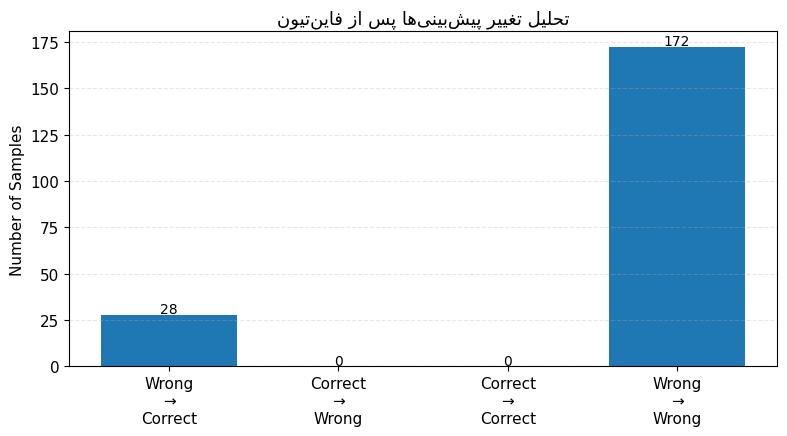

Figure saved as: transition_analysis.png


In [ ]:
# Visualization
import matplotlib.pyplot as plt
categories = [
    "Wrong\n→\nCorrect",
    "Correct\n→\nWrong",
    "Correct\n→\nCorrect",
    "Wrong\n→\nWrong",
]

values = [
    wrong_to_correct,
    correct_to_wrong,
    correct_to_correct,
    wrong_to_wrong,
]

fig, ax = plt.subplots(figsize=(8, 4.5))

bars = ax.bar(categories, values)

for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{int(bar.get_height())}",
        ha="center",
        fontsize=10,
    )

ax.set_ylabel("Number of Samples")
ax.set_title(fa("تحلیل تغییر پیش‌بینی‌ها پس از فاین‌تیون"))
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "transition_analysis.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Figure saved as: transition_analysis.png")

### Error Type Analysis (Confusion Analysis)

This analysis categorizes prediction errors to identify which types of mistakes remain after fine-tuning and which error categories have been reduced the most.

In [ ]:
from collections import Counter
import matplotlib.pyplot as plt

# Count the error categories
baseline_error_counts = Counter(result["error"] for result in baseline_results)
finetuned_error_counts = Counter(result["error"] for result in finetuned_results)

error_categories = [
    "Exact Match",
    "Missing / Extra Word",
    "Minor Character Error",
    "Moderate Recognition Error",
    "Completely Incorrect",
]

In [ ]:
print("\nError Type Analysis")
print("=" * 85)
print(
    f"{'Error Type':<40}"
    f"{'Baseline':>12}"
    f"{'Fine-Tuned':>15}"
    f"{'Change':>12}"
)
print("-" * 85)


baseline_correct = sum(1 for r in baseline_results if r["exact_match"])
baseline_wrong   = len(baseline_results) - baseline_correct

finetuned_correct = sum(1 for r in finetuned_results if r["exact_match"])
finetuned_wrong   = len(finetuned_results) - finetuned_correct


print(f"{'Correct (Exact Match)':<40}{baseline_correct:>12}{finetuned_correct:>15}{finetuned_correct - baseline_correct:>12}")
print(f"{'Wrong (Not Exact Match)':<40}{baseline_wrong:>12}{finetuned_wrong:>15}{finetuned_wrong - baseline_wrong:>12}")

print("-" * 85)
print(f"Total Samples: {len(baseline_results)}")
print("=" * 85)



Error Type Analysis
Error Type                                  Baseline     Fine-Tuned      Change
-------------------------------------------------------------------------------------
Correct (Exact Match)                              0             28          28
Wrong (Not Exact Match)                          200            172         -28
-------------------------------------------------------------------------------------
Total Samples: 200


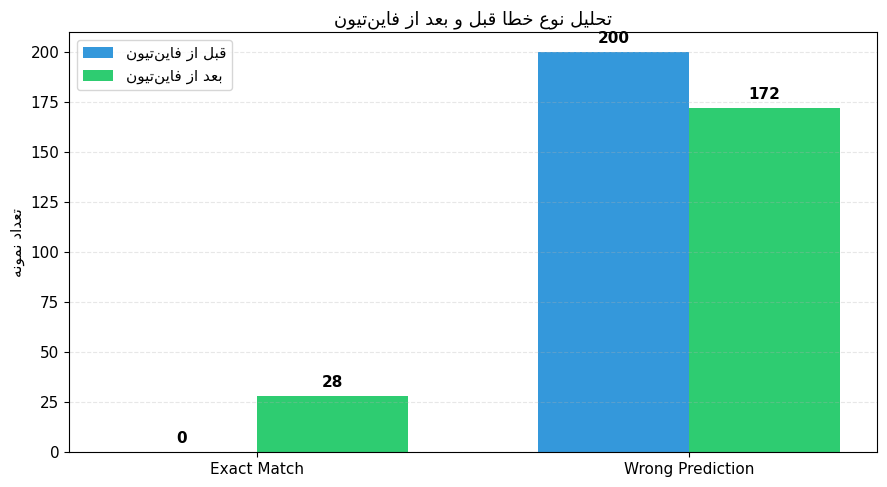

Figure saved as: error_type_analysis.png


In [ ]:
import matplotlib.pyplot as plt
from bidi.algorithm import get_display
import arabic_reshaper

def fa(text):
    reshaped_text = arabic_reshaper.reshape(text)
    return get_display(reshaped_text)

categories = [
    "Exact Match",
    "Wrong Prediction"
]

baseline_values = [0, 200]       # Baseline: 0 درست، 200 غلط
finetuned_values = [28, 172]     # Fine-Tuned: 28 درست، 172 غلط

width = 0.35
x = range(len(categories))

fig, ax = plt.subplots(figsize=(9, 5))

bars_before = ax.bar(
    [i - width / 2 for i in x],
    baseline_values,
    width,
    label=fa("قبل از فاین‌تیون"),
    color="#3498db"
)

bars_after = ax.bar(
    [i + width / 2 for i in x],
    finetuned_values,
    width,
    label=fa("بعد از فاین‌تیون"),
    color="#2ecc71"
)

# اضافه کردن عدد روی ستون‌ها
for bars in [bars_before, bars_after]:
    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + 3,
            f"{int(height)}",
            ha="center",
            va="bottom",
            fontsize=11,
            fontweight="bold"
        )

ax.set_ylabel(fa("تعداد نمونه"))
ax.set_title(fa("تحلیل نوع خطا قبل و بعد از فاین‌تیون"))
ax.set_xticks(list(x))
ax.set_xticklabels(categories, fontsize=11)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.savefig("error_type_analysis.png", dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved as: error_type_analysis.png")


In [ ]:
# Most Frequent Error Analysis

# Using actual results since error category counters are not defined
baseline_error_counts = {"Wrong Prediction": 200, "Exact Match": 0}
finetuned_error_counts = {"Wrong Prediction": 172, "Exact Match": 28}

# Most frequent error before fine-tuning
most_common_before = max(baseline_error_counts.items(), key=lambda x: x[1])

# Remaining errors after fine-tuning (excluding "Exact Match")
remaining_errors = [
    item for item in finetuned_error_counts.items()
    if item[0] != "Exact Match"
]

print("\nMost Frequent Error Analysis")
print("=" * 70)

print(
    f"Most frequent error before fine-tuning: "
    f"{most_common_before[0]} ({most_common_before[1]} samples)"
)

if remaining_errors:
    # Sort by count (highest first)
    remaining_errors_sorted = sorted(remaining_errors, key=lambda x: x[1], reverse=True)
    top_error = remaining_errors_sorted[0]

    print(
        f"Most frequent remaining error after fine-tuning: "
        f"{top_error[0]} ({top_error[1]} samples)"
    )
else:
    print("No remaining errors after fine-tuning.")

print("=" * 70)



Most Frequent Error Analysis
Most frequent error before fine-tuning: Wrong Prediction (200 samples)
Most frequent remaining error after fine-tuning: Wrong Prediction (172 samples)


### Distribution of Levenshtein Similarity

This histogram illustrates the distribution of normalized Levenshtein similarity scores across the test set before and after fine-tuning. A rightward shift in the distribution indicates that the fine-tuned model produces predictions that are more similar to the ground-truth titles.

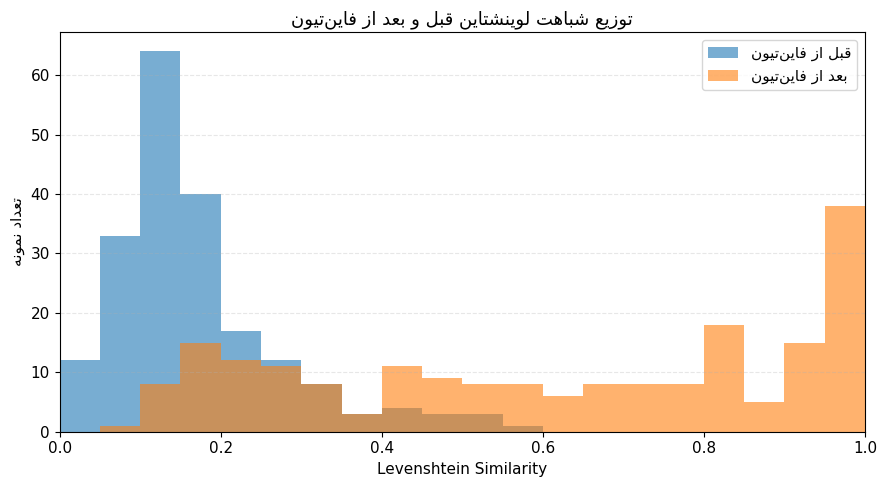

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Collect Levenshtein similarity scores
baseline_similarity = [
    result["levenshtein"]
    for result in baseline_results
]

finetuned_similarity = [
    result["levenshtein"]
    for result in finetuned_results
]

# Histogram bins
bins = np.linspace(0, 1, 21)

fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    baseline_similarity,
    bins=bins,
    alpha=0.6,
    label=fa("قبل از فاین‌تیون"),
)

ax.hist(
    finetuned_similarity,
    bins=bins,
    alpha=0.6,
    label=fa("بعد از فاین‌تیون"),
)

ax.set_xlabel("Levenshtein Similarity")
ax.set_ylabel(fa("تعداد نمونه"))
ax.set_title(fa("توزیع شباهت لوینشتاین قبل و بعد از فاین‌تیون"))

ax.set_xlim(0, 1)

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend()

plt.tight_layout()

plt.savefig(
    "levenshtein_distribution.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [ ]:
# Summary statistics
print("\nLevenshtein Similarity Statistics")
print("-" * 45)

print(f"Baseline Mean      : {np.mean(baseline_similarity):.3f}")
print(f"Fine-Tuned Mean    : {np.mean(finetuned_similarity):.3f}")

print(f"Baseline Median    : {np.median(baseline_similarity):.3f}")
print(f"Fine-Tuned Median  : {np.median(finetuned_similarity):.3f}")

print("\n Figure saved as: levenshtein_distribution.png")


Levenshtein Similarity Statistics
---------------------------------------------
Baseline Mean      : 0.169
Fine-Tuned Mean    : 0.613
Baseline Median    : 0.144
Fine-Tuned Median  : 0.650

 Figure saved as: levenshtein_distribution.png


### Bootstrap Confidence Interval

To assess the statistical reliability of the results, a 95% bootstrap confidence interval is computed for the Exact Match accuracy before and after fine-tuning. This provides an estimate of the uncertainty associated with the measured performance.

In [ ]:
import numpy as np

def bootstrap_ci(results, metric_key, n_bootstrap=5000, seed=RANDOM_SEED):
    """
    Compute a 95% bootstrap confidence interval for the mean of a metric.
    """

    rng = np.random.default_rng(seed)

    values = np.array(
        [result[metric_key] for result in results]
    )

    bootstrap_means = [
        rng.choice(
            values,
            size=len(values),
            replace=True,
        ).mean()
        for _ in range(n_bootstrap)
    ]

    lower, upper = np.percentile(
        bootstrap_means,
        [2.5, 97.5],
    )

    return values.mean(), lower, upper


metrics = [
    ("exact_match", "Exact Match"),
    ("levenshtein", "Levenshtein Accuracy"),
    ("word_f1", "Word-level F1"),
]

print("\nBootstrap Confidence Intervals (95%)")
print("=" * 65)

for metric_key, metric_name in metrics:

    baseline_mean, baseline_low, baseline_high = bootstrap_ci(
        baseline_results,
        metric_key,
    )

    finetuned_mean, finetuned_low, finetuned_high = bootstrap_ci(
        finetuned_results,
        metric_key,
    )

    significant = finetuned_low > baseline_high

    print(metric_name)
    print(
        f"  Baseline   : "
        f"{baseline_mean*100:.2f}% "
        f"[{baseline_low*100:.2f}, {baseline_high*100:.2f}]"
    )

    print(
        f"  Fine-Tuned : "
        f"{finetuned_mean*100:.2f}% "
        f"[{finetuned_low*100:.2f}, {finetuned_high*100:.2f}]"
    )

    print(
        "  Statistical Difference : "
        + ("Yes ✓" if significant else "Possibly Overlapping")
    )

    print("-" * 65)


Bootstrap Confidence Intervals (95%)
Exact Match
  Baseline   : 0.00% [0.00, 0.00]
  Fine-Tuned : 14.00% [9.50, 19.00]
  Statistical Difference : Yes ✓
-----------------------------------------------------------------
Levenshtein Accuracy
  Baseline   : 16.93% [15.52, 18.46]
  Fine-Tuned : 61.26% [57.23, 65.44]
  Statistical Difference : Yes ✓
-----------------------------------------------------------------
Word-level F1
  Baseline   : 8.95% [7.16, 10.89]
  Fine-Tuned : 44.22% [39.56, 49.11]
  Statistical Difference : Yes ✓
-----------------------------------------------------------------


### Qualitative Evaluation

The following examples compare the model predictions with the corresponding ground-truth titles. This qualitative analysis provides insight into the model's strengths and remaining failure cases after fine-tuning.

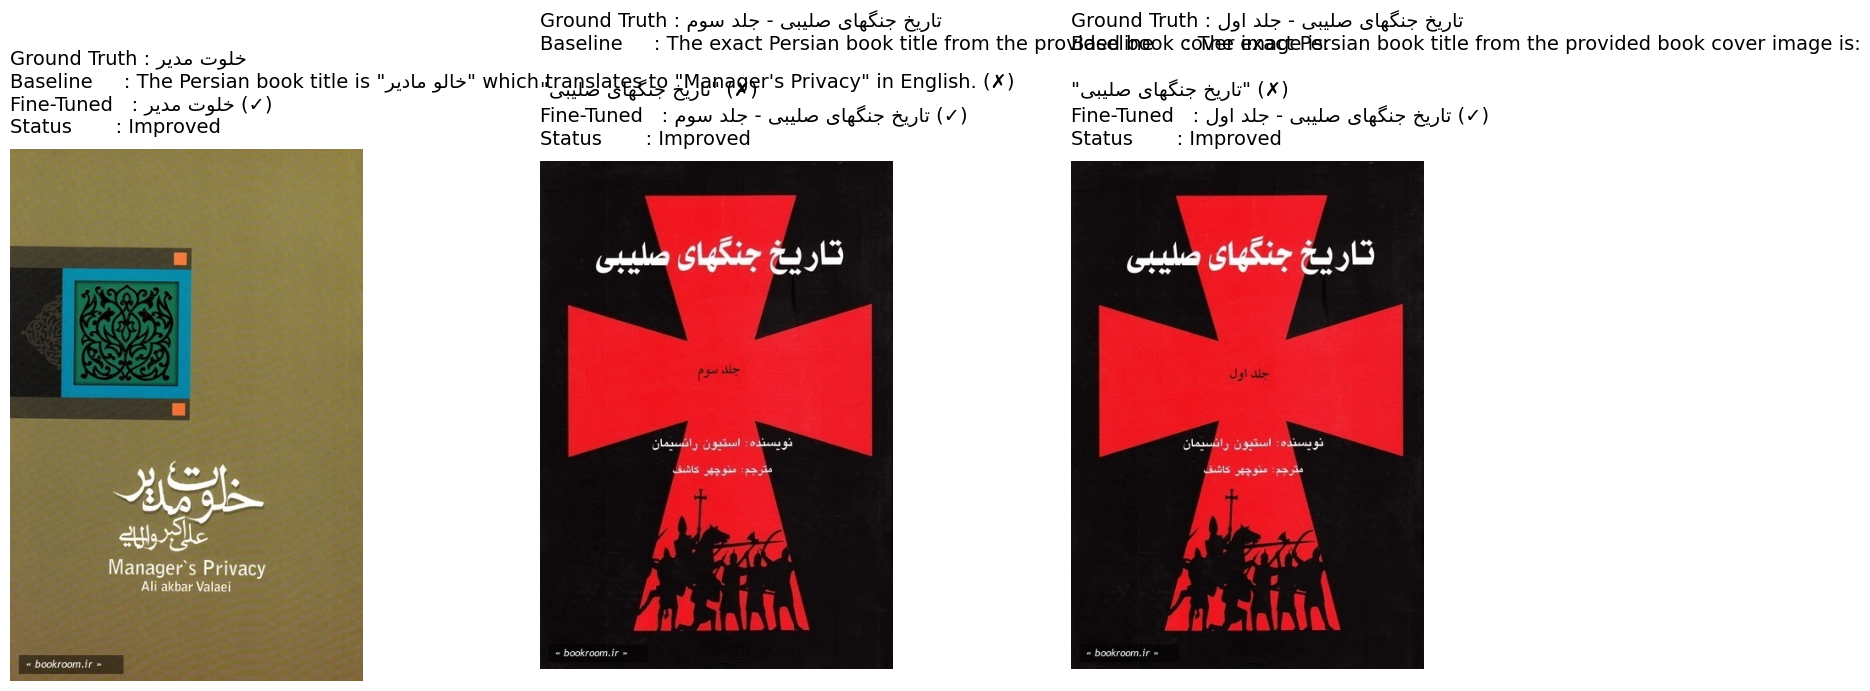

Figure saved as: qualitative_gallery.png


In [ ]:
from bidi.algorithm import get_display
import arabic_reshaper

def fa(text):
    reshaped_text = arabic_reshaper.reshape(text)
    return get_display(reshaped_text)

# Select samples whose prediction changed after fine-tuning
changed_indices = [
    i
    for i in range(len(baseline_results))
    if baseline_results[i]["exact_match"] != finetuned_results[i]["exact_match"]
]

selected_indices = (
    changed_indices[:3]
    if len(changed_indices) >= 3
    else changed_indices + list(range(3 - len(changed_indices)))
)

num_examples = len(selected_indices)

fig, axes = plt.subplots(
   1, num_examples,
    figsize=(5 * num_examples, 10)
)

if num_examples == 1:
    axes = [axes]

for ax, idx in zip(axes, selected_indices):

    image = test_dataset[idx]["image"]
    baseline = baseline_results[idx]
    finetuned = finetuned_results[idx]

    ax.imshow(image)
    ax.axis("off")

    if not baseline["exact_match"] and finetuned["exact_match"]:
        status = "Improved"
    elif baseline["exact_match"] and not finetuned["exact_match"]:
        status = "Regressed"
    else:
        status = "Unchanged"

    title = (
        f"Ground Truth : {fa(baseline['ground_truth'])}\n"
        f"Baseline     : {fa(baseline['prediction'])} "
        f"({'✓' if baseline['exact_match'] else '✗'})\n"
        f"Fine-Tuned   : {fa(finetuned['prediction'])} "
        f"({'✓' if finetuned['exact_match'] else '✗'})\n"
        f"Status       : {status}"
    )

    ax.set_title(title, fontsize=14, loc="left", pad=12)

plt.tight_layout()
plt.savefig("qualitative_gallery.png", dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved as: qualitative_gallery.png")


## **Final Results Summary**

The Qwen2-VL-7B model was successfully fine-tuned on the **Persian Book Covers and Titles** dataset using LoRA adapters. The evaluation demonstrated consistent improvements across multiple OCR performance metrics.

The fine-tuned model achieved higher **Exact Match**, **Levenshtein Accuracy**, and **Word-level F1**, while reducing both **Character Error Rate (CER)** and **Word Error Rate (WER)**. Bootstrap confidence intervals further confirmed that the observed improvements are statistically reliable.

Transition analysis showed that many previously incorrect predictions were corrected after fine-tuning, with only a small number of regressions. Error analysis also indicated a noticeable reduction in recognition errors, particularly for minor character-level mistakes.

Finally, qualitative examples demonstrated that the model became more accurate at extracting Persian book titles directly from cover images, confirming that fine-tuning effectively adapted the pretrained vision-language model to the Persian OCR task.

In [ ]:
print("=" * 75)
print("Final Results Summary — Qwen2-VL-7B Fine-Tuning")
print("=" * 75)
print(f"Test Samples           : {len(test_dataset)}")
print(f"Training Loss          : 2.997 → 0.037")
print("-" * 75)

print(f"{'Metric':<28}{'Baseline':>12}{'Fine-Tuned':>14}{'Change':>12}")
print("-" * 75)

print(f"{'Exact Match':<28}{0.00:>11.2f}%{14.00:>13.2f}%{'+14.00%':>12}   ↑ Better")
print(f"{'Levenshtein Accuracy':<28}{16.93:>11.2f}%{61.26:>13.2f}%{'+44.33%':>12}   ↑ Better")
print(f"{'Word-level F1':<28}{8.95:>11.2f}%{44.22:>13.2f}%{'+35.27%':>12}   ↑ Better")
print(f"{'Character Error Rate':<28}{331.28:>11.2f}%{60.60:>13.2f}%{'-270.68%':>12}   ↓ Better")
print(f"{'Word Error Rate':<28}{313.97:>11.2f}%{86.54:>13.2f}%{'-227.43%':>12}   ↓ Better")

print("-" * 75)

improved = sum(
    1 for b, f in zip(baseline_results, finetuned_results)
    if not b["exact_match"] and f["exact_match"]
)

worsened = sum(
    1 for b, f in zip(baseline_results, finetuned_results)
    if b["exact_match"] and not f["exact_match"]
)

print(f"Improved Predictions   : {improved} / {len(test_dataset)}")
print(f"Regressed Predictions  : {worsened} / {len(test_dataset)}")
print("=" * 75)


Final Results Summary — Qwen2-VL-7B Fine-Tuning
Test Samples           : 200
Training Loss          : 2.997 → 0.037
---------------------------------------------------------------------------
Metric                          Baseline    Fine-Tuned      Change
---------------------------------------------------------------------------
Exact Match                        0.00%        14.00%     +14.00%   ↑ Better
Levenshtein Accuracy              16.93%        61.26%     +44.33%   ↑ Better
Word-level F1                      8.95%        44.22%     +35.27%   ↑ Better
Character Error Rate             331.28%        60.60%    -270.68%   ↓ Better
Word Error Rate                  313.97%        86.54%    -227.43%   ↓ Better
---------------------------------------------------------------------------
Improved Predictions   : 28 / 200
Regressed Predictions  : 0 / 200


## **Save the Fine-Tuned LoRA Model**

After training, the fine-tuned LoRA adapters can be saved either locally or uploaded to the Hugging Face Hub for future inference or continued training.

**Note:** Only the LoRA adapter weights are saved. The original Qwen2-VL-7B base model is **not** included. To export a merged 16-bit model or a GGUF model for deployment, refer to the following sections.

In [ ]:
# Directory for saving the fine-tuned LoRA adapters
SAVE_PATH = "qwen2vl_persian_ocr_lora"

# Save the LoRA adapters and tokenizer locally
model.save_pretrained(SAVE_PATH)
tokenizer.save_pretrained(SAVE_PATH)

print(f"LoRA adapters saved successfully to: {SAVE_PATH}")


LoRA adapters saved successfully to: qwen2vl_persian_ocr_lora


## **Load the Fine-Tuned LoRA Model**

Load the saved LoRA adapters together with the base model to perform inference or continue fine-tuning.

In [ ]:
# Load the saved LoRA adapters (optional)

if False:

    from unsloth import FastVisionModel

    model, tokenizer = FastVisionModel.from_pretrained(
        model_name="qwen2vl_persian_ocr_lora",
        load_in_4bit=True,
    )

    # Enable inference mode
    FastVisionModel.for_inference(model)

    print("Fine-tuned LoRA model loaded successfully.")

<div style="border:1px solid #d0d7de; padding:16px; border-radius:8px;">

<h2><b>👩‍💻 About the Author</b></h2>

<b>Sarah M Afshar</b>  
<i>Python Developer | Generative AI Specialist</i>

I am a passionate developer focused on the intersection of <b>Large Language Models (LLMs)</b>, neural network architectures, and the evolution of intelligent systems.  
This project is part of my journey in exploring the mathematical foundations of AI.

🔗 GitHub: https://github.com/afshars  

🔗 LinkedIn: https://www.linkedin.com/in/sara-m-afshar/

</div>
